# EDA · Real Food Classifier · Análisis

Continuación de `01_eda.ipynb`. Partimos del dataset limpio (`data/processed/off_nova_clean.csv.gz`, 48.119 productos) y analizamos cómo se relaciona cada variable con la clase NOVA.

**Todo el análisis se hace solo con train.** El test se reserva para evaluar los modelos: si lo miramos ahora para tomar decisiones (transformaciones, variables), la métrica final saldría optimista.

## Paso 9 · Carga y comprobación del split

Cargamos el CSV limpio, separamos train y comprobamos que el split fijo conserva la proporción de clases.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA = Path("../data/processed/off_nova_clean.csv.gz")
df = pd.read_csv(DATA, dtype={"code": str})

print(df["split"].value_counts())
train = df[df["split"] == "train"].copy()

split
train    38495
test      9624
Name: count, dtype: int64


In [2]:
# Si StratifiedGroupKFold funcionó, las dos columnas deberían ser casi iguales
pd.crosstab(df["nova_group"], df["split"], normalize="columns").round(3)

split,test,train
nova_group,,
1,0.129,0.129
2,0.112,0.112
3,0.204,0.204
4,0.555,0.555


### 9.1 Resultados

- Train: 38.495 productos (80 %) · Test: 9.624 (20 %).
- Las proporciones de NOVA son **idénticas** en train y test (12,9 / 11,2 / 20,4 / 55,5 %): el `StratifiedGroupKFold` estratifica bien aunque agrupe por producto.

Agrupamos las columnas por tipo para usarlas en el resto del análisis: 9 nutrientes por 100 g, 10 marcadores `tiene_*` y 2 niveles de categoría.

In [3]:
OBJETIVO = "nova_group"
NO_MODELO = ["code", "product_name", "brands", "grupo_producto", "ingredients_text", "split"]

nutrientes  = [c for c in df.columns if c.endswith("_100g")]   # se buscan por sufijo, sin escribirlos a mano
marcadores  = [c for c in df.columns if c.startswith("tiene_")]
categoricas = ["pnns_groups_1", "pnns_groups_2"]
print(len(nutrientes), nutrientes)
print(len(marcadores), marcadores)

9 ['energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'fruits-vegetables-legumes_100g']
10 ['tiene_aromas', 'tiene_edulcorantes', 'tiene_jarabes', 'tiene_almidon_modificado', 'tiene_grasa_hidrogenada', 'tiene_proteina_aislada', 'tiene_colorantes', 'tiene_emulsionantes', 'tiene_potenciadores', 'tiene_aceite_palma']


## Paso 10 · Categoría del producto

`pnns_groups_1` (12 categorías) y `pnns_groups_2` (42 subcategorías) clasifican el producto por tipo de alimento. Miramos cómo se reparte NOVA dentro de cada categoría y decidimos qué nivel entra al modelo.

### 10.1 NOVA por categoría (`pnns_groups_1`)

pnns_groups_1
Sugary snacks              7385
unknown                    5293
Fat and sauces             4932
Cereals and potatoes       4811
Milk and dairy products    3805
Beverages                  3663
Fish Meat Eggs             2777
Fruits and vegetables      2358
Salty snacks               1649
Composite foods            1418
Alcoholic beverages         277
Baby foods                  127
Name: count, dtype: int64

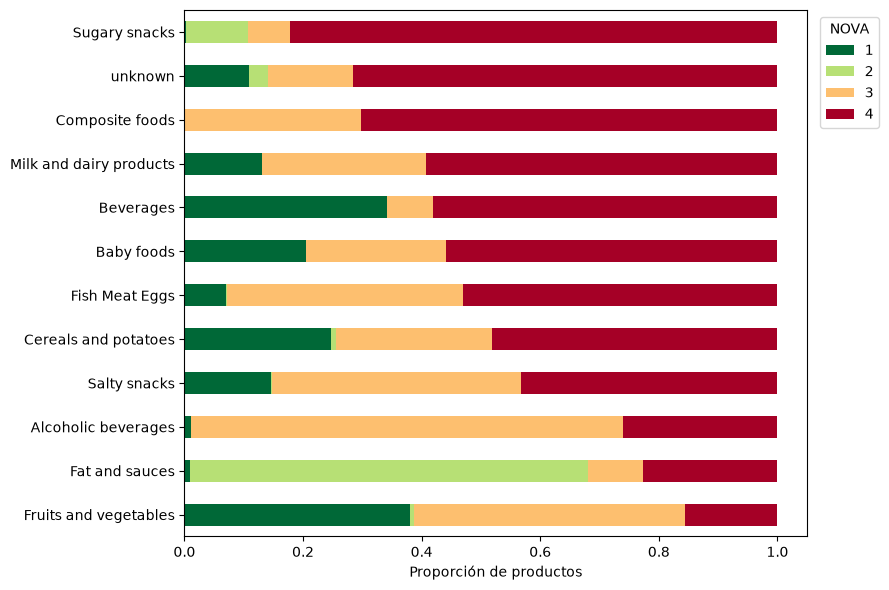

In [4]:
tabla = pd.crosstab(train["pnns_groups_1"], train[OBJETIVO], normalize="index")
orden = tabla[4].sort_values().index        # ordenadas por % de ultraprocesados

ax = tabla.loc[orden].plot(kind="barh", stacked=True, figsize=(9, 6), colormap="RdYlGn_r")
ax.set_xlabel("Proporción de productos")
ax.set_ylabel("")
ax.legend(title="NOVA", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

train["pnns_groups_1"].value_counts()       # el tamaño de cada categoría importa: un 100 % sobre 12 productos no dice mucho

**Resultados** (train, ordenadas por % de NOVA 4):

| Categoría | Productos | NOVA 1 | NOVA 2 | NOVA 3 | NOVA 4 |
|---|---|---|---|---|---|
| Fruits and vegetables | 2.358 | 38 % | 1 % | 46 % | 16 % |
| Fat and sauces | 4.932 | 1 % | 67 % | 9 % | 23 % |
| Alcoholic beverages | 277 | 1 % | 0 % | 73 % | 26 % |
| Salty snacks | 1.649 | 15 % | 0 % | 42 % | 43 % |
| Cereals and potatoes | 4.811 | 25 % | 1 % | 26 % | 48 % |
| Fish Meat Eggs | 2.777 | 7 % | 0 % | 40 % | 53 % |
| Baby foods | 127 | 21 % | 0 % | 24 % | 56 % |
| Beverages | 3.663 | 34 % | 0 % | 8 % | 58 % |
| Milk and dairy products | 3.805 | 13 % | 0 % | 28 % | 59 % |
| Composite foods | 1.418 | 0 % | 0 % | 30 % | 70 % |
| unknown | 5.293 | 11 % | 3 % | 14 % | 72 % |
| Sugary snacks | 7.385 | 0 % | 10 % | 7 % | 82 % |

**Conclusiones:**
- **La clase 2 está casi toda en `Fat and sauces`** (aceites, mantequilla, vinagres) y en menor medida en `Sugary snacks` (azúcar, miel). En el resto de categorías es prácticamente 0. La categoría será clave para reconocer la clase 2.
- **`Sugary snacks` (82 %) y `Composite foods` (70 %)** son mayoritariamente ultraprocesados. `Composite foods` no tiene ningún NOVA 1.
- **`unknown` no es neutra:** tiene un 72 % de NOVA 4, por encima de la media (55,5 %). Confirma que conviene mantenerla como categoría propia y no imputarla.
- **Categorías mezcladas:** en `Fruits and vegetables` (fresco frente a conserva), `Salty snacks` (frutos secos frente a patatas fritas) y `Cereals and potatoes` la categoría sola no basta. Ahí tendrán que trabajar los ingredientes y los nutrientes.
- Todas las categorías tienen tamaño suficiente; la más pequeña es `Baby foods`, con 127 productos en train. A este nivel no hay categorías raras.

### 10.2 NOVA por subcategoría (`pnns_groups_2`)

Cada subcategoría pertenece a una sola categoría de nivel 1. Miramos si el nivel 2 separa mejor las clases y cuántas subcategorías tienen muy pocos productos.

In [5]:
# Comprobación: si sale 1, cada subcategoría está dentro de una única categoría de nivel 1
print(train.groupby("pnns_groups_2")["pnns_groups_1"].nunique().max())

# % de cada clase dentro de cada subcategoría, agrupado por su categoría de nivel 1
tabla2 = pd.crosstab([train["pnns_groups_1"], train["pnns_groups_2"]], train[OBJETIVO], normalize="index")
tabla2["n"] = train.groupby(["pnns_groups_1", "pnns_groups_2"]).size()
tabla2.round(2)

1


nova_group                                                   1     2     3  \
pnns_groups_1           pnns_groups_2                                        
Alcoholic beverages     Alcoholic beverages               0.01  0.00  0.73   
Baby foods              Baby foods                        0.26  0.00  0.30   
                        Baby milks                        0.00  0.00  0.00   
Beverages               Artificially sweetened beverages  0.00  0.00  0.00   
                        Fruit juices                      0.88  0.00  0.01   
                        Fruit nectars                     0.34  0.00  0.00   
                        Plant-based milk substitutes      0.08  0.00  0.18   
                        Sweetened beverages               0.01  0.00  0.19   
                        Teas and herbal teas and coffees  0.64  0.00  0.07   
                        Unsweetened beverages             0.48  0.00  0.06   
                        Waters and flavored waters        0.98  0.00  0.00   
Cereals and potatoes    Bread                             0.01  0.00  0.34   
                        Breakfast cereals                 0.12  0.00  0.21   
                        Cereals                           0.54  0.03  0.12   
                        Legumes                           0.35  0.00  0.43   
                        Potatoes                          0.02  0.00  0.43   
Composite foods         One-dish meals                    0.00  0.00  0.37   
                        Pizza pies and quiches            0.00  0.00  0.14   
                        Sandwiches                        0.00  0.00  0.11   
Fat and sauces          Dressings and sauces              0.03  0.18  0.25   
                        Fats                              0.00  0.96  0.00   
Fish Meat Eggs          Eggs                              0.85  0.00  0.08   
                        Fish and seafood                  0.08  0.00  0.69   
                        Meat                              0.07  0.00  0.16   
                        Offals                            0.00  0.00  0.75   
                        Processed meat                    0.00  0.00  0.18   
Fruits and vegetables   Dried fruits                      0.36  0.00  0.49   
                        Fruits                            0.65  0.03  0.15   
                        Soups                             0.00  0.00  0.67   
                        Vegetables                        0.40  0.00  0.49   
Milk and dairy products Cheese                            0.00  0.00  0.63   
                        Dairy desserts                    0.03  0.00  0.09   
                        Ice cream                         0.00  0.00  0.02   
                        Milk and yogurt                   0.32  0.00  0.09   
Salty snacks            Appetizers                        0.00  0.00  0.38   
                        Nuts                              0.47  0.00  0.36   
                        Salty and fatty products          0.03  0.00  0.54   
Sugary snacks           Biscuits and cakes                0.00  0.00  0.07   
                        Chocolate products                0.00  0.00  0.12   
                        Pastries                          0.00  0.00  0.06   
                        Sweets                            0.01  0.23  0.05   
unknown                 unknown                           0.11  0.03  0.14   

nova_group                                                   4     n  
pnns_groups_1           pnns_groups_2                                 
Alcoholic beverages     Alcoholic beverages               0.26   277  
Baby foods              Baby foods                        0.45   101  
                        Baby milks                        1.00    26  
Beverages               Artificially sweetened beverages  1.00   877  
                        Fruit juices                      0.11   370  
                        Fruit nectars                     0.66    35  

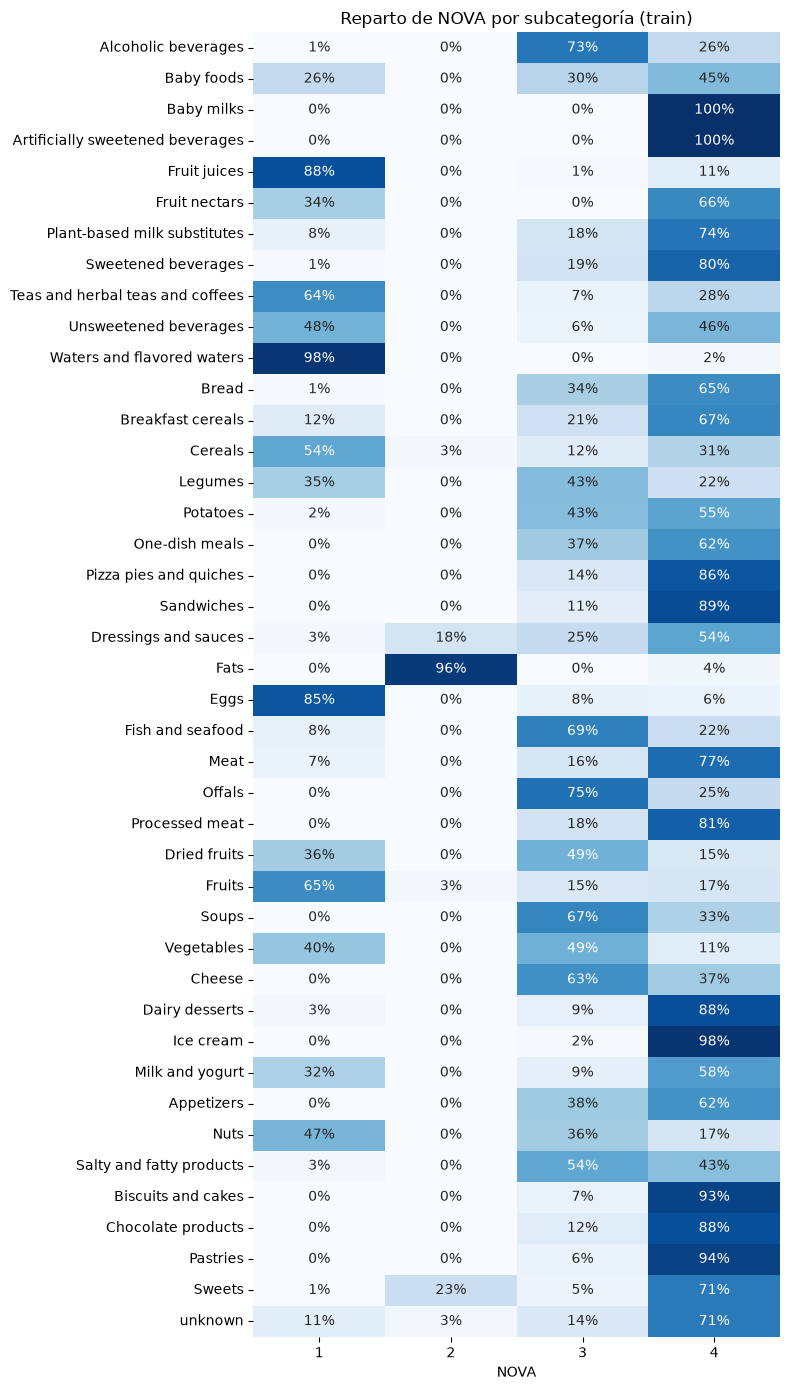

In [6]:
# 42 filas: un heatmap se lee mejor que 42 barras apiladas
fig, ax = plt.subplots(figsize=(8, 14))
sns.heatmap(
    tabla2[[1, 2, 3, 4]].droplevel(0),   # quitamos el nivel 1 de las etiquetas para que no sean tan largas
    annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax
)
ax.set_xlabel("NOVA")
ax.set_ylabel("")
ax.set_title("Reparto de NOVA por subcategoría (train)")
plt.tight_layout()

In [7]:
conteo2 = train["pnns_groups_2"].value_counts()

# Probamos varios umbrales para ver cuántas subcategorías y productos quedarían como "raros"
for umbral in [30, 50, 100]:
    raras = conteo2[conteo2 < umbral]
    print(f"< {umbral}: {len(raras)} subcategorías, {raras.sum()} productos")

conteo2[conteo2 < 100]

< 30: 2 subcategorías, 42 productos
< 50: 3 subcategorías, 77 productos
< 100: 4 subcategorías, 139 productos


pnns_groups_2
Eggs             62
Fruit nectars    35
Baby milks       26
Offals           16
Name: count, dtype: int64

**Resultados:**
- El nivel 2 está **anidado** en el nivel 1: cada subcategoría pertenece a una sola categoría.
- **Separa mucho mejor las clases** que el nivel 1. Algunos ejemplos:
  - `Fat and sauces` mezclaba dos cosas: `Fats` es 96 % NOVA 2 y `Dressings and sauces` es 54 % NOVA 4.
  - En `Beverages`: `Waters and flavored waters` es 98 % NOVA 1, `Fruit juices` 88 % NOVA 1 y `Artificially sweetened beverages` 100 % NOVA 4.
  - En `Fish Meat Eggs`: `Eggs` es 85 % NOVA 1, `Fish and seafood` 69 % NOVA 3 y `Processed meat` 81 % NOVA 4.
- Siguen mezcladas: `Cereals` (54 % NOVA 1 / 31 % NOVA 4), `Legumes`, `Vegetables`, `Dried fruits`, `Nuts` y `Milk and yogurt` (fresco frente a preparado). Ahí decidirán los ingredientes.
- La clase 2 está en `Fats` (96 %: aceites y mantequillas), `Sweets` (23 %: miel y azúcar) y `Dressings and sauces` (18 %: casi todo vinagres). En `unknown`, `Cereals` y `Fruits` es residual.

**Subcategorías raras** (train):

| Umbral | Subcategorías | Productos |
|---|---|---|
| < 30 | 2 (`Offals` 16, `Baby milks` 26) | 42 |
| < 50 | 3 (+ `Fruit nectars` 35) | 77 |
| < 100 | 4 (+ `Eggs` 62) | 139 |

Son muy pocas y suman menos del 0,4 % del train.

### 10.3 Decisiones (propuesta para el equipo)

- **Entra al modelo `pnns_groups_2`** (42 categorías + `unknown`) porque es más informativa. `pnns_groups_1` es redundante (anidada) y no hace falta. Si se usaran las dos en la regresión logística, las variables estarían duplicadas.
- **Subcategorías raras:** no se tocan en el CSV. En la fase 2 se agrupan dentro del pipeline con `OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist")`, que calcula la frecuencia solo con train y manda a la categoría "infrecuente" cualquier subcategoría nueva que aparezca en test o en la app.
- **App:** elegir entre 42 subcategorías en un formulario es incómodo. Gemini puede proponerla a partir de la foto, y la usuaria la confirma en un desplegable.

## Paso 11 · Nutrientes por clase

NOVA no clasifica por composición nutricional, pero la composición puede ayudar a distinguir clases, sobre todo la 1, la 2 y la 3, donde los marcadores `tiene_*` no aparecen. Usamos la **mediana** porque los nutrientes tienen colas largas (aceites, sal, azúcar).

### 11.1 Medianas y distribución

In [8]:
# Mediana de cada nutriente por clase (filas = nutrientes, columnas = NOVA)
medianas = train.groupby(OBJETIVO)[nutrientes].median().T.round(1)
medianas

nova_group,1,2,3,4
energy-kcal_100g,74.0,881.0,219.0,274.0
fat_100g,1.0,99.0,8.2,8.2
saturated-fat_100g,0.2,13.0,1.6,2.0
carbohydrates_100g,9.4,0.0,7.0,26.0
sugars_100g,2.9,0.0,1.4,5.6
fiber_100g,2.7,0.0,1.7,1.8
proteins_100g,3.4,0.0,7.4,5.6
salt_100g,0.0,0.0,0.9,0.4
fruits-vegetables-legumes_100g,0.0,0.0,0.0,0.0


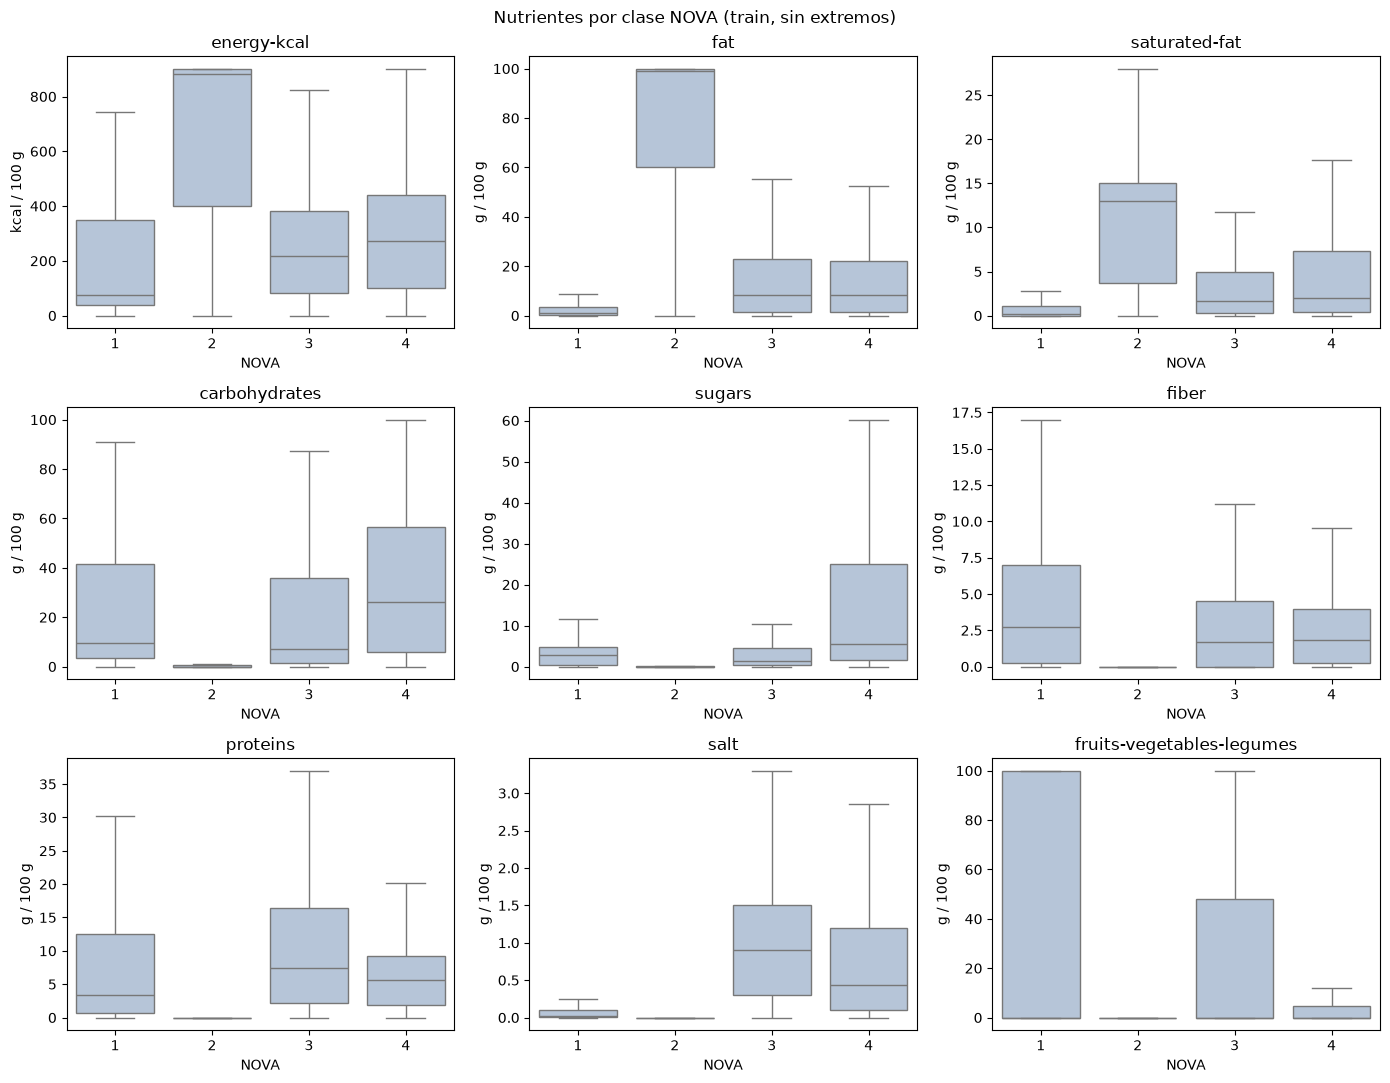

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))

for ax, col in zip(axes.flat, nutrientes):
    # showfliers=False oculta los extremos: con ellos las cajas quedan aplastadas y no se ven las diferencias
    sns.boxplot(data=train, x=OBJETIVO, y=col, showfliers=False, color="lightsteelblue", ax=ax)
    ax.set_title(col.replace("_100g", ""))
    ax.set_xlabel("NOVA")
    ax.set_ylabel("kcal / 100 g" if "energy" in col else "g / 100 g")

plt.suptitle("Nutrientes por clase NOVA (train, sin extremos)")
plt.tight_layout()

**Resultados** (medianas por 100 g, train):

| Nutriente | NOVA 1 | NOVA 2 | NOVA 3 | NOVA 4 |
|---|---|---|---|---|
| Energía (kcal) | 74 | 881 | 219 | 274 |
| Grasa | 1,0 | 99,0 | 8,2 | 8,2 |
| Saturadas | 0,2 | 13,0 | 1,6 | 2,0 |
| Hidratos | 9,4 | 0,0 | 7,0 | 26,0 |
| Azúcares | 2,9 | 0,0 | 1,4 | 5,6 |
| Fibra | 2,7 | 0,0 | 1,7 | 1,8 |
| Proteínas | 3,4 | 0,0 | 7,4 | 5,6 |
| Sal | 0,0 | 0,0 | 0,9 | 0,4 |
| Fruta, verdura y legumbres | 0,0 | 0,0 | 0,0 | 0,0 |

**Conclusiones:**
- **NOVA 2 es inconfundible** por su composición: mediana de 99 g de grasa y 881 kcal (aceites), con hidratos, proteínas y fibra a 0. Junto con `Fats` (paso 10), es la clase más fácil de reconocer.
- **NOVA 1** es lo menos calórico (74 kcal): aguas, frutas, verduras, leche y huevos. Casi sin sal.
- **NOVA 3** tiene la sal más alta (0,9 g): quesos, conservas y embutidos curados. También la proteína más alta (7,4 g).
- **NOVA 4** tiene más hidratos (26 g) y azúcares (5,6 g) que el resto, pero sus cajas se solapan mucho con las de NOVA 3. **Los nutrientes solos no separan 3 y 4**: ahí dependemos de los marcadores y de `n_ingredientes`.
- **Fruta, verdura y legumbres** tiene mediana 0 en todas las clases (el 54 % de los productos tiene 0). Solo aporta información en la cola.

### 11.2 ¿Los nulos dependen de la clase?

Los nulos que quedan se imputan en la fase 2. Antes de elegir cómo, comprobamos si faltan al azar o se concentran en alguna clase.

In [10]:
# % de nulos de cada nutriente dentro de cada clase
nulos_clase = train.groupby(OBJETIVO)[nutrientes].apply(lambda g: g.isna().mean() * 100).T.round(1)
nulos_clase[nulos_clase.max(axis=1) > 5]   # solo los nutrientes con más de un 5 % de nulos en alguna clase

nova_group,1,2,3,4
energy-kcal_100g,1.2,7.7,0.2,0.3
fat_100g,1.9,10.2,0.9,0.9
saturated-fat_100g,4.7,7.6,1.7,2.2
carbohydrates_100g,2.1,10.3,0.9,0.7
sugars_100g,4.3,8.8,1.7,1.5
fiber_100g,14.2,77.9,19.7,34.3
proteins_100g,1.9,10.7,0.8,0.8
salt_100g,1.8,9.1,1.7,2.2
fruits-vegetables-legumes_100g,7.3,86.0,0.6,1.0


In [11]:
# Fruta/verdura/legumbres es una estimación de Open Food Facts a partir de los ingredientes:
# si no hay lista de ingredientes, no se puede calcular
print(pd.crosstab(train["fruits-vegetables-legumes_100g"].isna(), train["sin_lista_ingredientes"]))
print()
print(pd.crosstab(train["fiber_100g"].isna(), train["sin_lista_ingredientes"]))

sin_lista_ingredientes              0     1
fruits-vegetables-legumes_100g             
False                           34160     0
True                              344  3991

sin_lista_ingredientes      0     1
fiber_100g                         
False                   25072   486
True                     9432  3505


**Resultados** (% de nulos por clase, train):

| Nutriente | NOVA 1 | NOVA 2 | NOVA 3 | NOVA 4 |
|---|---|---|---|---|
| Fibra | 14 % | **78 %** | 20 % | 34 % |
| Fruta, verdura y legumbres | 7 % | **86 %** | 1 % | 1 % |

**Los nulos no son aleatorios: se concentran en la clase 2.**
- **Resto de nutrientes:** en las clases 1, 3 y 4 faltan como mucho en un 5 % de los productos, pero en la clase 2 faltan en un 8-11 %. Son productos con la tabla nutricional incompleta, sobre todo mieles (278 de los 461 NOVA 2 sin proteínas).
- **Fruta, verdura y legumbres:** de los 4.335 nulos, 3.991 (92 %) son productos sin lista de ingredientes. Open Food Facts la estima a partir de los ingredientes, así que sin lista no puede calcularla. Este nulo repite la información de `sin_lista_ingredientes`.
- **Fibra:** en la UE es **voluntario** declararla en la tabla nutricional (Reglamento 1169/2011), por eso falta en un 33 % de los productos. Los aceites casi nunca la declaran porque no tienen.

**Implicaciones para la fase 2:**
- Imputar la fibra con la mediana global (1,7 g) daría fibra a los aceites, que no tienen. Opciones: imputar con la mediana **por subcategoría** o usar `SimpleImputer(strategy="median", add_indicator=True)`, que además añade una columna 0/1 "faltaba la fibra". Esa columna aporta información porque los nulos dependen de la clase.
- Fruta, verdura y legumbres: la mediana es 0, así que imputar con la mediana da un valor razonable.
- **App:** como la fibra es voluntaria, en la etiqueta real a veces no aparecerá. El modelo tiene que aceptar ese campo vacío en el formulario, y el pipeline con imputador lo resuelve.

## Paso 12 · Ingredientes, aditivos y marcadores

### 12.1 Variables asimétricas

`n_ingredientes` y `additives_n` cuentan cosas: muchos productos tienen valores bajos y unos pocos llegan a valores muy altos. La sal tiene el mismo problema (la propia sal tiene 100 g). Medimos la asimetría (*skewness*) antes y después de aplicar `log1p` (log(1 + x), que admite ceros).

In [12]:
asimetricas = ["n_ingredientes", "additives_n", "salt_100g"]

# skew ≈ 0: simétrica · > 1: cola larga a la derecha
pd.DataFrame({
    "skew": train[asimetricas].skew(),
    "skew_log1p": np.log1p(train[asimetricas]).skew(),
}).round(1)

,skew,skew_log1p
n_ingredientes,5.0,0.0
additives_n,2.3,0.6
salt_100g,16.4,2.3


In [13]:
# Mediana y P75: con tantos ceros, la mediana sola esconde diferencias (p. ej. en additives_n)
pd.concat(
    {"mediana": train.groupby(OBJETIVO)[asimetricas].median(),
     "p75": train.groupby(OBJETIVO)[asimetricas].quantile(0.75)},
    axis=1,
).round(2)

mediana                                  p75              \
           n_ingredientes additives_n salt_100g n_ingredientes additives_n   
nova_group                                                                   
1                     1.0         0.0      0.02            2.0         0.0   
2                     1.0         0.0      0.00            1.0         0.0   
3                     4.0         0.0      0.90            6.0         1.0   
4                     9.0         3.0      0.43           14.0         5.0   

                      
           salt_100g  
nova_group            
1                0.1  
2                0.0  
3                1.5  
4                1.2

nova_group
1    94.7
2    99.0
3    72.4
4    13.2
Name: additives_n, dtype: float64

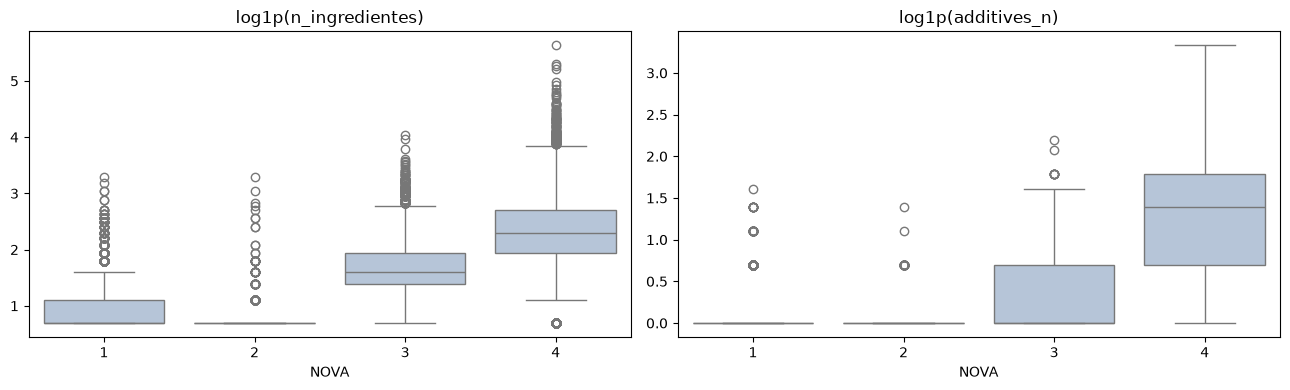

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, ["n_ingredientes", "additives_n"]):
    # boxplot de log1p: con la escala original, NOVA 4 aplasta al resto
    sns.boxplot(x=train[OBJETIVO], y=np.log1p(train[col]), color="lightsteelblue", ax=ax)
    ax.set_title(f"log1p({col})")
    ax.set_xlabel("NOVA")
    ax.set_ylabel("")

plt.tight_layout()

# % de productos sin ningún aditivo en cada clase
(train["additives_n"] == 0).groupby(train[OBJETIVO]).mean().mul(100).round(1)

**Resultados** (train):

| Variable | Skew | Skew con log1p | Máximo |
|---|---|---|---|
| `n_ingredientes` | 5,0 | 0,0 | 279 |
| `additives_n` | 2,3 | 0,6 | 27 |
| `salt_100g` | 16,4 | 2,3 | 100 |

| NOVA | `n_ingredientes` (mediana / P75) | `additives_n` (mediana / P75) | Sin aditivos |
|---|---|---|---|
| 1 | 1 / 2 | 0 / 0 | 95 % |
| 2 | 1 / 1 | 0 / 0 | 99 % |
| 3 | 4 / 6 | 0 / 1 | 72 % |
| 4 | 9 / 14 | 3 / 5 | 13 % |

**Conclusiones:**
- **`n_ingredientes` separa bien 1-2 de 3 y de 4:** los productos sin procesar y los ingredientes culinarios tienen 1 o 2 ingredientes; los procesados, unos 4; y los ultraprocesados, 9 o más.
- **`additives_n`:** el 87 % de los NOVA 4 lleva algún aditivo, frente al 5 % de los NOVA 1. Es una de las variables más claras para separar 4 del resto.
- **`log1p` corrige la asimetría** de `n_ingredientes` (5,0 → 0,0) y `additives_n` (2,3 → 0,6). Con la sal mejora pero sigue siendo asimétrica (2,3), por los productos que son casi sal pura.
- **Fase 2:** aplicar `log1p` a estas tres variables en la regresión logística y en KNN (sensibles a la escala y a los extremos), antes de escalar. Los árboles (Random Forest, XGBoost, LightGBM) no lo necesitan.

### 12.2 Marcadores de ultraprocesado (`tiene_*`)

En el paso 7 vimos que los marcadores aparecen casi solo en NOVA 4. Medimos cuánto aparece cada uno por clase y cuántos productos quedan sin explicar.

nova_group,1,2,3,4,total
tiene_aromas,0.0,0.0,0.0,61.2,34.0
tiene_emulsionantes,0.0,0.0,0.0,47.2,26.2
tiene_jarabes,0.6,0.2,1.3,34.1,19.3
tiene_colorantes,0.0,0.0,1.2,23.4,13.2
tiene_edulcorantes,0.0,0.0,0.0,13.4,7.5
tiene_almidon_modificado,0.0,0.0,0.0,12.9,7.2
tiene_aceite_palma,0.1,0.0,1.7,11.1,6.5
tiene_proteina_aislada,0.0,0.0,0.1,11.2,6.2
tiene_potenciadores,0.0,0.0,0.0,5.0,2.8
tiene_grasa_hidrogenada,0.0,0.0,0.2,0.9,0.6


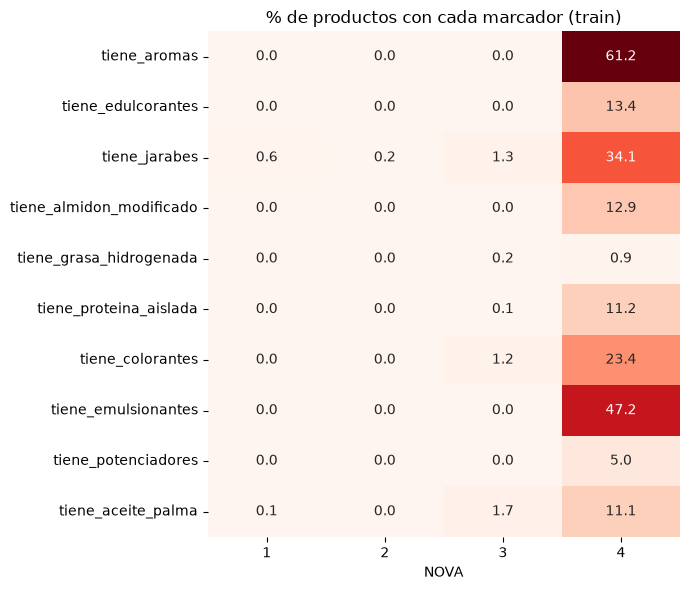

In [15]:
pct_marcadores = (train.groupby(OBJETIVO)[marcadores].mean() * 100).T.round(1)
pct_marcadores["total"] = (train[marcadores].mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(pct_marcadores.drop(columns="total"), annot=True, fmt=".1f", cmap="Reds", cbar=False, ax=ax)
ax.set_xlabel("NOVA")
ax.set_ylabel("")
ax.set_title("% de productos con cada marcador (train)")
plt.tight_layout()

pct_marcadores.sort_values("total", ascending=False)

In [16]:
# ¿Algún marcador presente?
alguno = train[marcadores].sum(axis=1) > 0

print("NOVA 4 sin ningún marcador:", f"{(~alguno[train[OBJETIVO] == 4]).mean():.1%}")
print("\nOtras clases con algún marcador:")
print(alguno[train[OBJETIVO] != 4].groupby(train[OBJETIVO]).mean().mul(100).round(1))

NOVA 4 sin ningún marcador: 7.1%

Otras clases con algún marcador:
nova_group
1    0.7
2    0.3
3    4.1
dtype: float64


**Resultados** (% de productos con el marcador, train):

| Marcador | NOVA 1 | NOVA 2 | NOVA 3 | NOVA 4 |
|---|---|---|---|---|
| Aromas | 0 | 0 | 0 | 61,2 |
| Emulsionantes (E4xx) | 0 | 0 | 0 | 47,2 |
| Jarabes | 0,6 | 0,2 | 1,3 | 34,1 |
| Colorantes (E1xx) | 0 | 0 | 1,2 | 23,4 |
| Edulcorantes | 0 | 0 | 0 | 13,4 |
| Almidón modificado | 0 | 0 | 0 | 12,9 |
| Proteína aislada | 0 | 0 | 0,1 | 11,2 |
| Aceite de palma | 0,1 | 0 | 1,7 | 11,1 |
| Potenciadores (E62x-63x) | 0 | 0 | 0 | 5,0 |
| Grasa hidrogenada | 0 | 0 | 0,2 | 0,9 |

**Conclusiones:**
- **Los marcadores son casi exclusivos de NOVA 4:** solo el 7,1 % de los NOVA 4 no tiene ninguno, y en las otras clases aparecen en menos del 5 % de los productos (NOVA 1: 0,7 %, NOVA 2: 0,3 %, NOVA 3: 4,1 %).
- Esto confirma el aviso del paso 7: Open Food Facts asigna NOVA en parte con estas mismas reglas. **Es esperable que el modelo reconozca muy bien NOVA 4.** El mérito real estará en separar 1, 2 y 3, así que hay que mirar el recall de esas clases y no solo el F1 global.
- **Marcadores poco útiles:** `tiene_grasa_hidrogenada` aparece en el 0,6 % de los productos (0,9 % de los NOVA 4) y `tiene_potenciadores` en el 2,8 %. Aportan poco al modelo y, en la app, son dos casillas más del formulario.

**Para decidir en equipo** (lista final de marcadores = casillas del formulario):
- ¿Quitamos `tiene_grasa_hidrogenada`? Desde 2021 la UE limita las grasas trans (Reglamento 2019/649) y casi no aparece en los datos.
- ¿Mantenemos `tiene_potenciadores`? Es raro, pero cuando aparece (glutamato) es muy claro.

## Paso 13 · Correlaciones

Usamos la correlación de **Spearman**, que trabaja con rangos: no le afectan los extremos ni la asimetría, y detecta relaciones monótonas aunque no sean lineales.

Buscamos dos cosas:
- **Variables redundantes entre sí** (|r| ≥ 0,6): pueden dar problemas en la regresión logística (colinealidad) y pesar el doble en las distancias de KNN.
- **Relación de cada variable con NOVA**, con cuidado: NOVA es ordinal, pero la relación con la clase no tiene por qué ser monótona.

### 13.1 Correlación entre variables

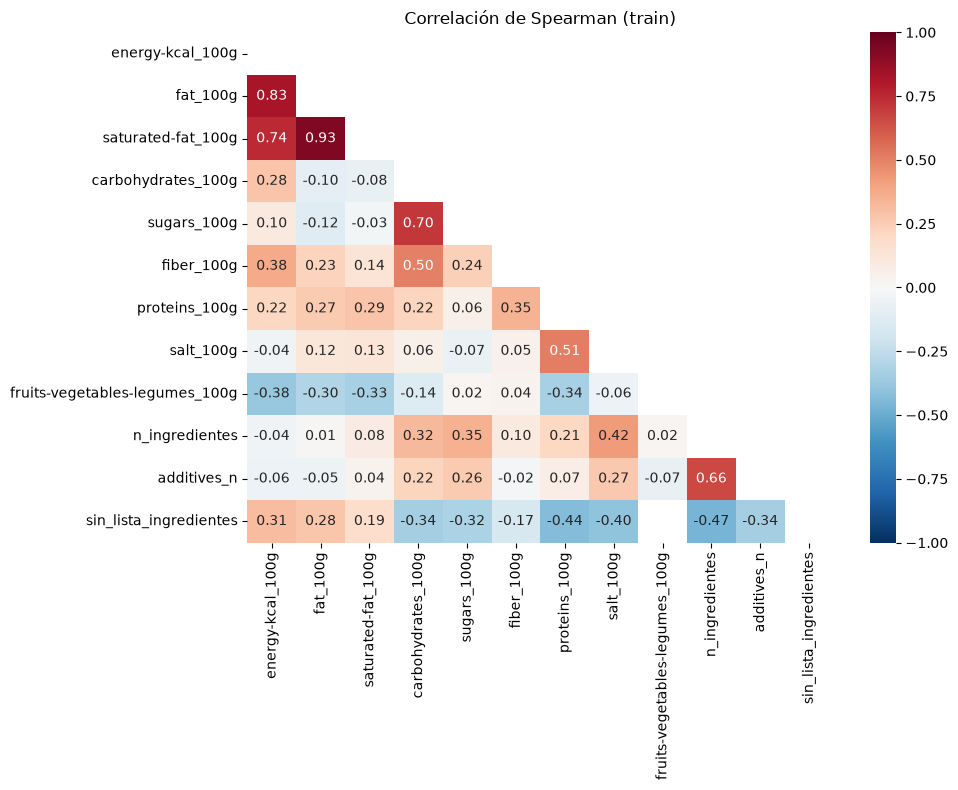

In [17]:
numericas = nutrientes + ["n_ingredientes", "additives_n", "sin_lista_ingredientes"]
corr = train[numericas].corr(method="spearman")

# Máscara del triángulo superior: la matriz es simétrica, así se lee la mitad
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Spearman (train)")
plt.tight_layout()

In [18]:
corr_todas = train[numericas + marcadores].corr(method="spearman")

# Nos quedamos con cada pareja una sola vez (triángulo superior, sin la diagonal)
parejas = corr_todas.where(np.triu(np.ones_like(corr_todas, dtype=bool), k=1)).stack()
parejas[parejas.abs() >= 0.6].sort_values(key=abs, ascending=False).round(2)

fat_100g            saturated-fat_100g     0.93
energy-kcal_100g    fat_100g               0.83
                    saturated-fat_100g     0.74
carbohydrates_100g  sugars_100g            0.70
n_ingredientes      additives_n            0.66
additives_n         tiene_emulsionantes    0.66
dtype: float64

**Resultados** (|r| ≥ 0,6):

| Pareja | r |
|---|---|
| `fat_100g` · `saturated-fat_100g` | 0,93 |
| `energy-kcal_100g` · `fat_100g` | 0,83 |
| `energy-kcal_100g` · `saturated-fat_100g` | 0,74 |
| `carbohydrates_100g` · `sugars_100g` | 0,70 |
| `n_ingredientes` · `additives_n` | 0,66 |
| `tiene_emulsionantes` · `additives_n` | 0,66 |

**Conclusiones:**
- **Grasa y saturadas (0,93)** son casi la misma información. Lo mismo pasa con hidratos y azúcares (0,70), aunque en menor grado.
- **La energía es redundante con los macros.** Se calcula a partir de ellos (9·grasa + 4·hidratos + 4·proteína + 2·fibra) y en 840 productos la recalculamos con esa fórmula (paso 5).
- **`tiene_emulsionantes` y `additives_n` (0,66):** los emulsionantes son aditivos, así que esos productos cuentan dos veces: en el marcador y en el número de aditivos.
- Ninguna pareja es una copia exacta (r = 1), así que **no eliminamos variables en el CSV**.

**Para la fase 2:**
- **Árboles:** no les afecta la colinealidad. Se usan todas.
- **Regresión logística:** con regularización (L2, la de por defecto en scikit-learn) la colinealidad no rompe el modelo, pero los coeficientes de las variables correlacionadas no se pueden interpretar por separado. Opción: probar a quitar `energy-kcal_100g` y `saturated-fat_100g` y comparar el F1 macro.
- **KNN:** las variables redundantes pesan doble en la distancia (la grasa entra dos o tres veces). Conviene probar también sin ellas.

### 13.2 Relación con NOVA

n_ingredientes                    0.75
additives_n                       0.72
tiene_aromas                      0.61
tiene_emulsionantes               0.51
sin_lista_ingredientes           -0.42
tiene_jarabes                     0.40
sugars_100g                       0.35
salt_100g                         0.35
tiene_colorantes                  0.32
carbohydrates_100g                0.30
tiene_edulcorantes                0.24
tiene_almidon_modificado          0.24
tiene_proteina_aislada            0.22
tiene_aceite_palma                0.20
proteins_100g                     0.15
tiene_potenciadores               0.14
fruits-vegetables-legumes_100g   -0.12
saturated-fat_100g                0.09
tiene_grasa_hidrogenada           0.06
energy-kcal_100g                 -0.01
fat_100g                          0.01
fiber_100g                       -0.00
Name: nova_group, dtype: float64

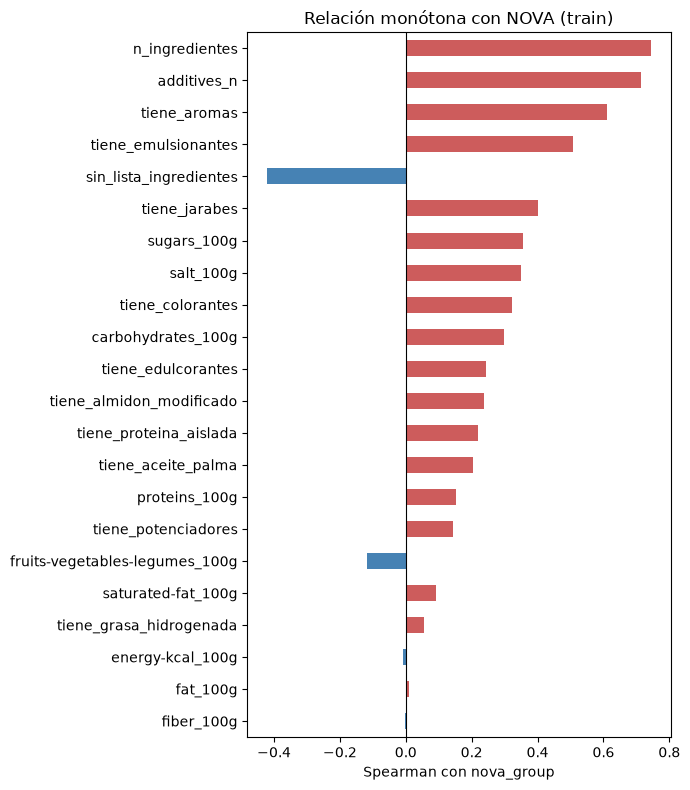

In [19]:
# Spearman con NOVA tratada como ordinal (1 < 2 < 3 < 4)
corr_nova = (
    train[numericas + marcadores + [OBJETIVO]]
    .corr(method="spearman")[OBJETIVO]
    .drop(OBJETIVO)
    .sort_values(key=abs)          # de menor a mayor |r| para que el barh quede con la mayor arriba
)

fig, ax = plt.subplots(figsize=(7, 8))
corr_nova.plot(kind="barh", color=np.where(corr_nova > 0, "indianred", "steelblue"), ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Spearman con nova_group")
ax.set_title("Relación monótona con NOVA (train)")
plt.tight_layout()

corr_nova.sort_values(key=abs, ascending=False).round(2)

**Resultados** (Spearman con `nova_group`, train):

| Variable | r |
|---|---|
| `n_ingredientes` | 0,75 |
| `additives_n` | 0,72 |
| `tiene_aromas` | 0,61 |
| `tiene_emulsionantes` | 0,51 |
| `sin_lista_ingredientes` | −0,42 |
| `tiene_jarabes` | 0,40 |
| `sugars_100g`, `salt_100g` | 0,35 |
| … | |
| `fat_100g` | 0,01 |
| `energy-kcal_100g` | −0,01 |
| `fiber_100g` | 0,00 |

**Conclusiones:**
- Las variables con más relación son las de **ingredientes y aditivos**: `n_ingredientes` (0,75), `additives_n` (0,72) y los marcadores. Coincide con la definición de NOVA (grado de procesamiento, no composición).
- **Una correlación baja no significa que la variable no sirva.** La grasa y la energía tienen r ≈ 0, pero en el paso 11 vimos que **identifican la clase 2** (mediana de 99 g de grasa y 881 kcal). La relación no es monótona: la grasa sube en la clase 2 y vuelve a bajar en la 3 y la 4. Spearman solo mide si la variable sube o baja a la vez que la clase, así que no la detecta.
- **No descartamos variables por su correlación con NOVA.** La selección de variables se hace en la fase 2, con la importancia en los modelos y con validación cruzada.